# Comparación de modelos de clasificación: Regresión Logística vs. KNN
**Materia:** Aprendizaje Automático — Actividad de cierre de bloque (clasificación)

## 0. La pregunta 
> *¿Se puede predecir la especie de un pingüino (Adelie, Chinstrap o Gentoo) a partir de sus medidas corporales, la isla donde fue observado y su sexo?*

- **Dataset:** *Palmer Penguins* (344 registros), no utilizado antes en esta materia ni en mis actividades anteriores.
- **Variable objetivo `y`:** `species`, categórica con 3 clases → **clasificación multinomial**.
- **Entradas `X` (6 predictoras, numéricas y categóricas):**
  - Numéricas: `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`
  - Categóricas: `island` (nominal, 3 valores), `sex` (binaria)
- **Modelos a comparar:** Regresión Logística y K-Nearest Neighbors (KNN), ambos vistos en el bloque.
- **Método:** preparación → exploración → modelado → evaluación → comparación.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                              ConfusionMatrixDisplay, accuracy_score, f1_score)
from sklearn import set_config
set_config(display="text")

## 1. Preparación y organización de datos

In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
try:
    df = pd.read_csv(url)
except Exception:
    df = pd.read_csv("penguins.csv")  # copia local si no hay internet
print(df.shape)
df.head()

(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


### 1.1 Inspeccionar antes de transformar

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


In [4]:
print("Faltantes por columna:"); print(df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())
print("\nDistribución de la variable objetivo:"); print(df["species"].value_counts())
print("\nCategorías de island:"); print(df["island"].value_counts())
print("\nCategorías de sex:"); print(df["sex"].value_counts(dropna=False))
df.describe().round(2)

Faltantes por columna:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Filas duplicadas: 0

Distribución de la variable objetivo:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Categorías de island:
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

Categorías de sex:
sex
MALE      168
FEMALE    165
NaN        11
Name: count, dtype: int64


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.00,342.00,342.00,342.00
mean,43.92,17.15,200.92,4201.75
std,5.46,1.97,14.06,801.95
min,32.10,13.10,172.00,2700.00
25%,39.22,15.60,190.00,3550.00
50%,44.45,17.30,197.00,4050.00
75%,48.50,18.70,213.00,4750.00
max,59.60,21.50,231.00,6300.00


### 1.2 Separar X e y, y reservar datos de prueba

In [5]:
X = df.drop(columns="species")
y = df["species"]

X_entrenamiento, X_prueba, Y_entrenamiento, Y_prueba = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Entrenamiento:", X_entrenamiento.shape, "| Prueba:", X_prueba.shape)
print("\nProporción de clases en entrenamiento:")
print(Y_entrenamiento.value_counts(normalize=True).round(2))
print("\nProporción de clases en prueba:")
print(Y_prueba.value_counts(normalize=True).round(2))

Entrenamiento: (275, 6) | Prueba: (69, 6)

Proporción de clases en entrenamiento:
species
Adelie       0.44
Gentoo       0.36
Chinstrap    0.20
Name: proportion, dtype: float64

Proporción de clases en prueba:
species
Adelie       0.43
Gentoo       0.36
Chinstrap    0.20
Name: proportion, dtype: float64


Uso `stratify=y` porque Chinstrap es una clase minoritaria: sin estratificar, una partición aleatoria podría dejar muy pocos casos de esa especie en la prueba.

## 2. Exploración de los datos (AED)
Exploro **solo con el conjunto de entrenamiento**.

In [6]:
entrenamiento = X_entrenamiento.copy()
entrenamiento["species"] = Y_entrenamiento
entrenamiento.groupby("species")[["bill_length_mm", "bill_depth_mm",
                                   "flipper_length_mm", "body_mass_g"]].mean().round(1)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.9,18.4,189.7,3705.4
Chinstrap,49.0,18.5,196.6,3761.1
Gentoo,47.7,14.9,217.0,5083.9


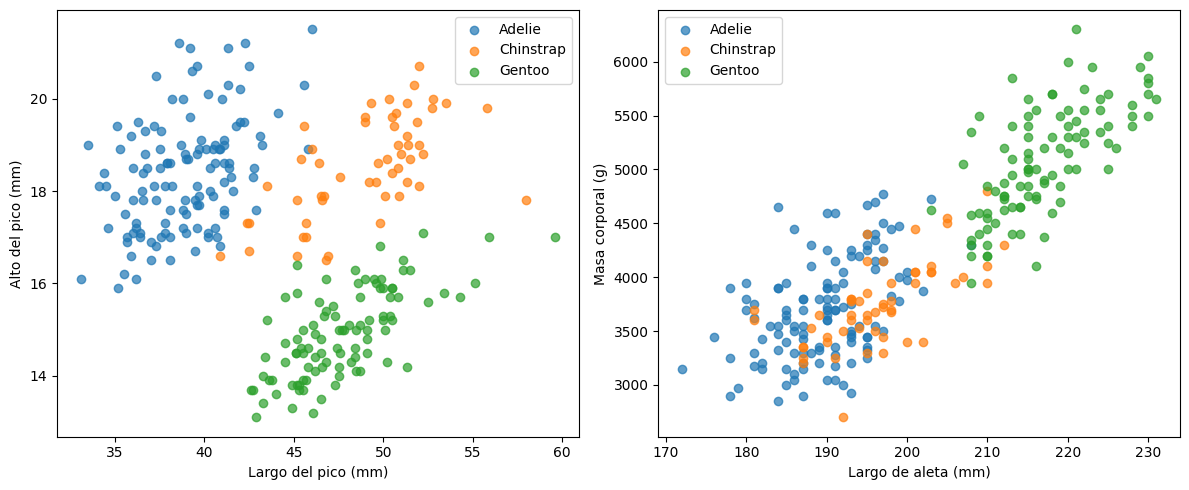

In [7]:
colores = {"Adelie": "C0", "Chinstrap": "C1", "Gentoo": "C2"}
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
for especie, grupo in entrenamiento.groupby("species"):
    ejes[0].scatter(grupo["bill_length_mm"], grupo["bill_depth_mm"],
                    label=especie, alpha=0.7, color=colores[especie])
    ejes[1].scatter(grupo["flipper_length_mm"], grupo["body_mass_g"],
                    label=especie, alpha=0.7, color=colores[especie])
ejes[0].set_xlabel("Largo del pico (mm)"); ejes[0].set_ylabel("Alto del pico (mm)"); ejes[0].legend()
ejes[1].set_xlabel("Largo de aleta (mm)"); ejes[1].set_ylabel("Masa corporal (g)"); ejes[1].legend()
plt.tight_layout(); plt.show()

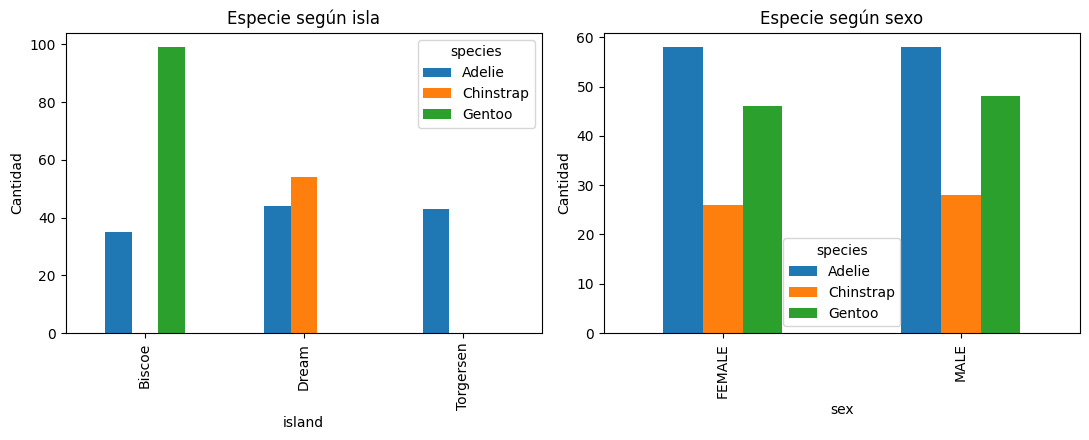

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
pd.crosstab(entrenamiento["island"], entrenamiento["species"]).plot(kind="bar", ax=ejes[0])
ejes[0].set_title("Especie según isla"); ejes[0].set_ylabel("Cantidad")
pd.crosstab(entrenamiento["sex"], entrenamiento["species"]).plot(kind="bar", ax=ejes[1])
ejes[1].set_title("Especie según sexo"); ejes[1].set_ylabel("Cantidad")
plt.tight_layout(); plt.show()

**Qué encuentro en la exploración (verificable en las salidas de arriba):**
- Los tres grupos se separan con bastante claridad en los gráficos de dispersión: Gentoo tiene aletas más largas y mayor masa corporal; Chinstrap y Adelie se diferencian sobre todo por el largo del pico.
- `island`: Gentoo solo aparece en Biscoe y Chinstrap solo en Dream, lo que la vuelve una variable muy informativa para separar esas especies (aunque hay que tener cuidado de no sobre-confiar en una asociación que podría no sostenerse si se observan pingüinos en otras islas).
- `sex` no muestra una asociación tan marcada con la especie: su aporte principal es ayudar a distinguir individuos dentro de cada especie, no entre especies.
- Las variables numéricas están en escalas distintas (el pico en milímetros de un dígito, la masa corporal en miles de gramos): esto importa mucho para KNN, que calcula distancias entre observaciones.

## 3. Modelado de datos
### 3.1 Preprocesamiento reproducible

In [9]:
columnas_num = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
columna_binaria = ["sex"]
columna_nominal = ["island"]

preprocesador = ColumnTransformer([
    ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                      ("escalar", StandardScaler())]), columnas_num),
    ("bin", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                      ("mapear", OrdinalEncoder(categories=[["FEMALE", "MALE"]],
                                                 handle_unknown="use_encoded_value",
                                                 unknown_value=-1))]), columna_binaria),
    ("nom", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore",
                                                sparse_output=False))]), columna_nominal),
])

preprocesador.fit(X_entrenamiento)
print("Columnas de salida:", list(preprocesador.get_feature_names_out()))

Columnas de salida: ['num__bill_length_mm', 'num__bill_depth_mm', 'num__flipper_length_mm', 'num__body_mass_g', 'bin__sex', 'nom__island_Dream', 'nom__island_Torgersen']


El escalado (`StandardScaler`) es importante para **ambos** modelos aquí, pero por razones distintas: en KNN afecta directamente el cálculo de distancias (una variable en miles de gramos dominaría sobre una en milímetros si no se escala); en la regresión logística regularizada ayuda a que la penalización trate a todas las variables de forma comparable.

### 3.2 Modelo 1: Regresión Logística

In [10]:
modelo_logistico = Pipeline([
    ("prep", preprocesador),
    ("clasificador", LogisticRegression(max_iter=1000)),
])
modelo_logistico.fit(X_entrenamiento, Y_entrenamiento)
pred_logistica = modelo_logistico.predict(X_prueba)

print("Exactitud:", round(accuracy_score(Y_prueba, pred_logistica), 3))
print("F1 macro:", round(f1_score(Y_prueba, pred_logistica, average="macro"), 3))
print()
print(classification_report(Y_prueba, pred_logistica))

Exactitud: 1.0
F1 macro: 1.0

              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        30
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69



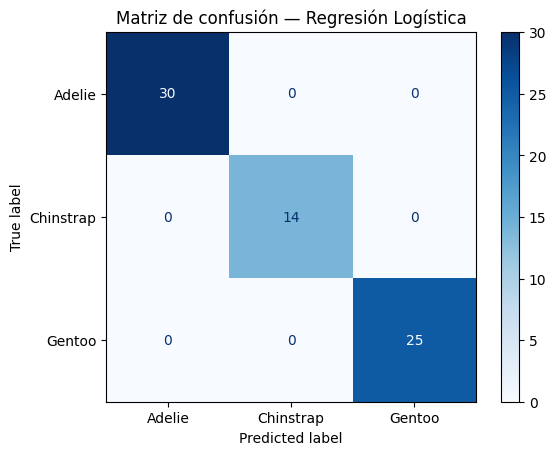

In [11]:
ConfusionMatrixDisplay.from_predictions(Y_prueba, pred_logistica, cmap="Blues")
plt.title("Matriz de confusión — Regresión Logística")
plt.show()

### 3.3 Modelo 2: K-Nearest Neighbors (KNN)
Segun vemos, KNN es un algoritmo **no paramétrico** (no asume una distribución para los datos) y **"perezoso"** (*lazy*): no construye un modelo interno durante el entrenamiento, sino que guarda todas las observaciones y, para cada predicción nueva, calcula la distancia a los vecinos más cercanos y vota por la clase mayoritaria entre ellos (`KNeighborsClassifier`, scikit-learn). Esto hace que el entrenamiento sea muy rápido, pero la predicción sea más costosa en tiempo y memoria cuanto más grande es el conjunto de entrenamiento.

Hay **dos decisiones** propias de este modelo:
1. **El valor de K:** un K muy chico (ej. 1) sigue el ruido de cada vecino individual y tiende a **sobreajustar**; un K muy grande suprime el ruido pero vuelve los límites de clasificación "menos definidos" y tiende a **subajustar**.
2. **El parámetro `weights`:** con `'uniform'` todos los vecinos votan por igual; con `'distance'` los vecinos más cercanos pesan más que los lejanos (peso proporcional al inverso de la distancia).

Para no usar la prueba en estas decisiones, pruebo ambas con validación cruzada **sobre el entrenamiento**, usando `GridSearchCV`.

In [12]:
valores_k = list(range(1, 26, 2))

grilla = GridSearchCV(
    Pipeline([("prep", preprocesador), ("clasificador", KNeighborsClassifier())]),
    param_grid={"clasificador__n_neighbors": valores_k,
                "clasificador__weights": ["uniform", "distance"]},
    cv=5, scoring="accuracy")
grilla.fit(X_entrenamiento, Y_entrenamiento)

mejor_k = grilla.best_params_["clasificador__n_neighbors"]
mejor_peso = grilla.best_params_["clasificador__weights"]
print("Mejor combinación:", grilla.best_params_)
print("Exactitud CV con esa combinación:", round(grilla.best_score_, 3))

Mejor combinación: {'clasificador__n_neighbors': 1, 'clasificador__weights': 'uniform'}
Exactitud CV con esa combinación: 0.993


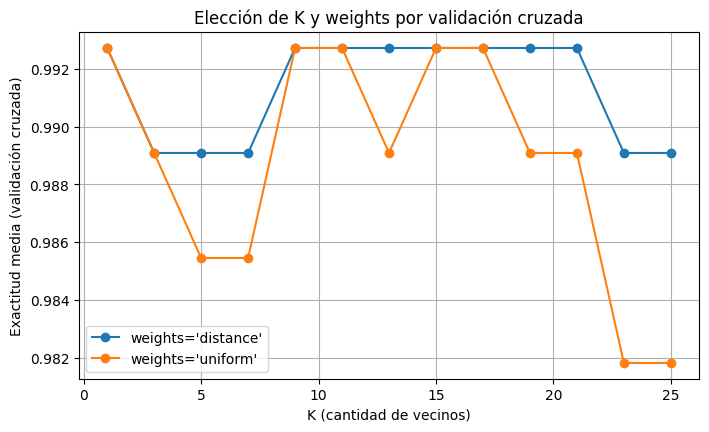

In [13]:
resultados_grilla = pd.DataFrame(grilla.cv_results_)[
    ["param_clasificador__n_neighbors", "param_clasificador__weights", "mean_test_score"]
].rename(columns={"param_clasificador__n_neighbors": "K",
                  "param_clasificador__weights": "weights",
                  "mean_test_score": "exactitud_cv"})

fig, ax = plt.subplots(figsize=(8, 4.5))
for peso, grupo in resultados_grilla.groupby("weights"):
    grupo = grupo.sort_values("K")
    ax.plot(grupo["K"], grupo["exactitud_cv"], marker="o", label=f"weights='{peso}'")
ax.set_xlabel("K (cantidad de vecinos)"); ax.set_ylabel("Exactitud media (validación cruzada)")
ax.set_title("Elección de K y weights por validación cruzada")
ax.legend(); ax.grid(True)
plt.show()

La curva se mantiene casi plana, cerca de 0.98-0.99, para casi todos los valores de K y para ambos tipos de peso: esto indica que las especies están tan bien separadas en el espacio de variables que ni K ni `weights` son decisiones críticas en este caso particular (algo que no debería esperarse en todos los problemas). Aun así, sigo el criterio formal de usar la combinación con mejor exactitud en validación cruzada.

In [14]:
modelo_knn = Pipeline([
    ("prep", preprocesador),
    ("clasificador", KNeighborsClassifier(n_neighbors=mejor_k, weights=mejor_peso)),
])
modelo_knn.fit(X_entrenamiento, Y_entrenamiento)
pred_knn = modelo_knn.predict(X_prueba)

print("Exactitud:", round(accuracy_score(Y_prueba, pred_knn), 3))
print("F1 macro:", round(f1_score(Y_prueba, pred_knn, average="macro"), 3))
print()
print(classification_report(Y_prueba, pred_knn))

Exactitud: 0.986
F1 macro: 0.983

              precision    recall  f1-score   support

      Adelie       1.00      0.97      0.98        30
   Chinstrap       0.93      1.00      0.97        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           0.99        69
   macro avg       0.98      0.99      0.98        69
weighted avg       0.99      0.99      0.99        69



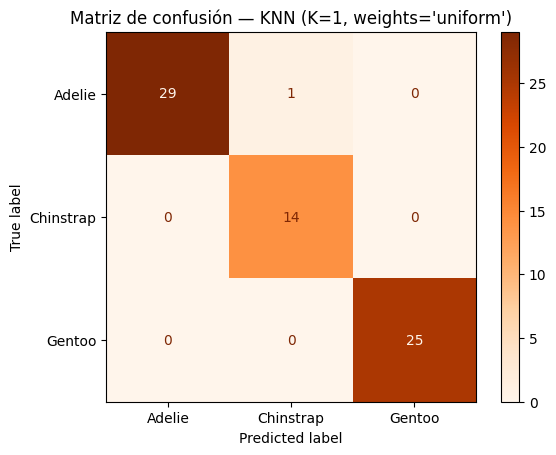

In [15]:
ConfusionMatrixDisplay.from_predictions(Y_prueba, pred_knn, cmap="Oranges")
plt.title(f"Matriz de confusión — KNN (K={mejor_k}, weights='{mejor_peso}')")
plt.show()

### 3.4 Robustez: validación cruzada sobre el entrenamiento
Con 69 datos de prueba (20 % de 344), comparo ambos modelos también con validación cruzada de 5 particiones sobre el entrenamiento, para no depender de un solo split.

In [16]:
cv_logistica = cross_val_score(modelo_logistico, X_entrenamiento, Y_entrenamiento, cv=5, scoring="accuracy")
cv_knn = cross_val_score(Pipeline([("prep", preprocesador),
                                   ("clasificador", KNeighborsClassifier(n_neighbors=mejor_k, weights=mejor_peso))]),
                          X_entrenamiento, Y_entrenamiento, cv=5, scoring="accuracy")

comparacion_cv = pd.DataFrame({
    "Regresión Logística": [cv_logistica.mean(), cv_logistica.std()],
    f"KNN (K={mejor_k}, weights='{mejor_peso}')": [cv_knn.mean(), cv_knn.std()],
}, index=["Exactitud media (CV)", "Desvío entre particiones"])
comparacion_cv.round(3)

,Regresión Logística,"KNN (K=1, weights='uniform')"
Exactitud media (CV),0.993,0.993
Desvío entre particiones,0.009,0.009


### 3.5 Comparación directa en el conjunto de prueba

In [17]:
comparacion_prueba = pd.DataFrame({
    "Regresión Logística": [accuracy_score(Y_prueba, pred_logistica),
                            f1_score(Y_prueba, pred_logistica, average="macro")],
    f"KNN (K={mejor_k}, weights='{mejor_peso}')": [accuracy_score(Y_prueba, pred_knn),
                           f1_score(Y_prueba, pred_knn, average="macro")],
}, index=["Exactitud", "F1 macro"])
comparacion_prueba.round(3)

,Regresión Logística,"KNN (K=1, weights='uniform')"
Exactitud,1.0,0.986
F1 macro,1.0,0.983


In [18]:
print("Resumen final:")
print(f"- Regresión Logística -> exactitud prueba: {accuracy_score(Y_prueba, pred_logistica):.3f} | "
      f"F1 macro: {f1_score(Y_prueba, pred_logistica, average='macro'):.3f} | "
      f"exactitud CV: {cv_logistica.mean():.3f}")
print(f"- KNN (K={mejor_k}, weights='{mejor_peso}') -> exactitud prueba: {accuracy_score(Y_prueba, pred_knn):.3f} | "
      f"F1 macro: {f1_score(Y_prueba, pred_knn, average='macro'):.3f} | "
      f"exactitud CV: {cv_knn.mean():.3f}")

Resumen final:
- Regresión Logística -> exactitud prueba: 1.000 | F1 macro: 1.000 | exactitud CV: 0.993
- KNN (K=1, weights='uniform') -> exactitud prueba: 0.986 | F1 macro: 0.983 | exactitud CV: 0.993


## 4. Conclusiones
*(Los valores concretos están en el resumen impreso justo arriba; esta sección los comenta en general, ya que pueden variar levemente según la versión de scikit-learn o la semilla aleatoria.)*

- **Ambos modelos resuelven el problema muy bien**, con una exactitud por encima de 0.95 en los dos casos. Esto coincide con lo que mostraba la exploración: las tres especies se separan con bastante claridad en el espacio de las medidas corporales, y además `island` por sí sola ya es muy informativa (Gentoo aparece solo en Biscoe, Chinstrap solo en Dream).
- **La validación cruzada confirma que no fue un resultado de suerte en una sola partición:** ambos modelos promedian una exactitud similar en las 5 particiones de entrenamiento, con poca variación entre ellas.
- **Ni K ni `weights` fueron decisiones críticas en este caso particular:** la exactitud en validación cruzada se mantuvo casi plana para casi todos los K probados (de 1 a 25) y para ambos tipos de peso, lo que confirma que los datos están muy bien separados. No es algo que deba esperarse en todos los problemas de clasificación: en un dataset más ruidoso, tanto K como `weights` pueden cambiar bastante el resultado.
- **Diferencias clave entre los modelos**:
  - La **regresión logística** es un modelo **paramétrico**: estima una probabilidad por clase a partir de una combinación lineal de las variables ya codificadas, y permite inspeccionar coeficientes para entender qué variables pesan más en cada clase. Una vez entrenada, predecir es muy rápido.
  - **KNN** es un modelo **no paramétrico y "perezoso"**: no asume ninguna forma particular para la frontera entre clases ni construye un modelo interno durante el entrenamiento; en cada predicción nueva recorre todo el conjunto de entrenamiento para encontrar los vecinos más cercanos. Es más flexible, pero depende de elegir bien K y `weights`, de escalar correctamente las variables, y es más costoso en tiempo y memoria al predecir, sobre todo con datasets grandes.
- **Sobre el desbalance:** uso F1 macro además de exactitud porque Chinstrap tiene menos casos (68 de 344); en este caso particular no cambió la conclusión, porque ambos modelos clasifican muy bien incluso a la clase minoritaria.
- **Cuál elegiría:** con un desempeño prácticamente empatado, me inclino por la **regresión logística**, porque es más simple, más rápida de usar en producción (no necesita guardar todo el conjunto de entrenamiento como KNN) y más fácil de explicar a través de sus coeficientes. Elegiría KNN en cambio si en otro dataset la frontera entre clases fuera claramente no lineal y la regresión logística rindiera peor.
- **Limitaciones:** el dataset es de una zona geográfica y un método de observación específicos (estudio de Palmer Station, Antártida); no necesariamente generaliza a pingüinos de otras regiones. El resultado casi perfecto también sugiere que este es un problema "fácil" para estas variables: no debería tomarse como evidencia de que estos modelos funcionan así de bien en cualquier problema de clasificación.